In [2]:
#Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [3]:
#Creating a Sample House Price Dataset
data = {
    "size_sqft": [
        500, 600, 700, 800, 900,
        1000, 1100, 1200, 1300, 1400,
        1500, 1600, 1700, 1800, 1900,
        2000
    ],
    "price_lakh": [
        25, 30, 35, 40, 44,
        50, 54, 60, 65, 69,
        75, 79, 85, 90, 94,
        100
    ]
}

df = pd.DataFrame(data)

df.head()

,size_sqft,price_lakh
0,500,25
1,600,30
2,700,35
3,800,40
4,900,44


In [4]:
print(df.shape)
print(df.describe())

(16, 2)
         size_sqft  price_lakh
count    16.000000     16.0000
mean   1250.000000     62.1875
std     476.095229     23.7184
min     500.000000     25.0000
25%     875.000000     43.0000
50%    1250.000000     62.5000
75%    1625.000000     80.5000
max    2000.000000    100.0000


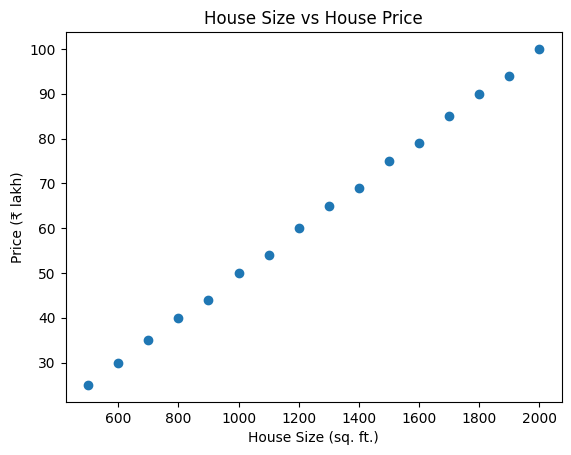

In [5]:
#Visualizing the data
plt.scatter(
    df["size_sqft"],
    df["price_lakh"]
)

plt.xlabel("House Size (sq. ft.)")
plt.ylabel("Price (₹ lakh)")
plt.title("House Size vs House Price")

plt.show()

In [6]:
#Separating the features and target
X = df[["size_sqft"]]

y = df["price_lakh"]

In [7]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (16, 1)
y shape: (16,)


In [8]:
#split Training and Testing Data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [9]:
print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 12
Testing examples: 4


In [11]:
#Regression Model
model = LinearRegression()

In [12]:
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.05]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['size_sqft']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.574
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [13]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 0.050180505415162474
Intercept: -0.5740072202166289


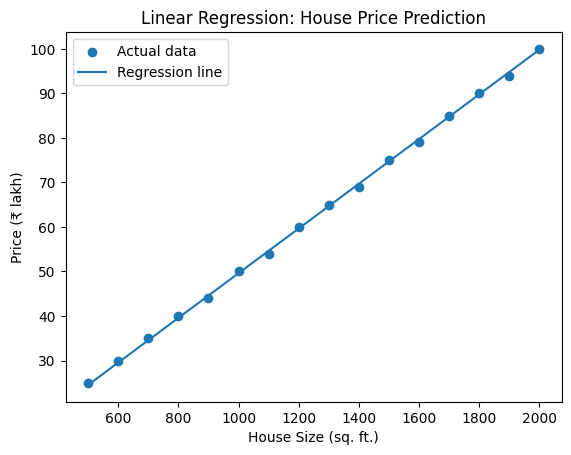

In [14]:
#Visualizing
plt.scatter(
    X["size_sqft"],
    y,
    label="Actual data"
)

plt.plot(
    X["size_sqft"],
    model.predict(X),
    label="Regression line"
)

plt.xlabel("House Size (sq. ft.)")
plt.ylabel("Price (₹ lakh)")
plt.title("Linear Regression: House Price Prediction")

plt.legend()
plt.show()

In [16]:
predictions = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": predictions
})

comparison

,Actual Price,Predicted Price
0,25,24.516245
1,30,29.534296
2,50,49.606498
3,94,94.768953


In [17]:
mae = mean_absolute_error(y_test, predictions)

print("MAE:", mae)

MAE: 0.5279783393501907


In [18]:
mse = mean_squared_error(y_test, predictions)

print("MSE:", mse)

MSE: 0.2992577773723214


In [19]:
rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 0.5470445844465709


In [20]:
r2 = r2_score(y_test, predictions)

print("R² Score:", r2)

R² Score: 0.999595700039014


In [21]:
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

MAE:  0.53
MSE:  0.30
RMSE: 0.55
R²:   0.9996


In [22]:
#Predicrt for a new house
new_house = pd.DataFrame({
    "size_sqft": [1750]
})

predicted_price = model.predict(new_house)

print(
    f"Predicted house price: ₹{predicted_price[0]:.2f} lakh"
)

Predicted house price: ₹87.24 lakh
